# Phase 2 — Benchmark de prédiction

Cette étape utilise les fenêtres de 7 jours produites par `05_structuration_fenetres.ipynb`. La séparation est chronologique : 70 % entraînement, 15 % validation et 15 % test. Aucun mélange aléatoire n'est effectué.

Les modèles comparés sont :
1. une moyenne d'entraînement ;
2. une persistance saisonnière à 1 jour ;
3. une Random Forest entraînée sur les 672 × 11 valeurs de chaque fenêtre.

In [1]:
from pathlib import Path
import json
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == 'notebooks':
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.benchmark import (
    flatten_windows,
    mean_forecast,
    seasonal_persistence_forecast,
    temporal_split_indices,
)
from src.metrics import regression_metrics
from src.models import build_random_forest

In [2]:
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
RESULTS_DIR = PROJECT_ROOT / 'results'
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

window_file = PROCESSED_DIR / 'sinert_windows_672.npz'
metadata_file = PROCESSED_DIR / 'sinert_windows_672_metadata.csv'
spec_file = PROCESSED_DIR / 'sinert_windows_672_spec.json'

with np.load(window_file) as dataset:
    X = dataset['X'].astype(np.float32)
    y = dataset['y'].astype(np.float32)
metadata = pd.read_csv(metadata_file, parse_dates=['window_start', 'window_end', 'target_timestamp'])
spec = json.loads(spec_file.read_text(encoding='utf-8'))

assert X.ndim == 3 and X.shape[1:] == (spec['window_size_steps'], len(spec['feature_columns']))
assert len(X) == len(y) == len(metadata)
assert np.isfinite(X).all() and np.isfinite(y).all()

print(f'X : {X.shape}')
print(f'y : {y.shape}')
print(f'Variables : {len(spec["feature_columns"])}')
print(f'Période des cibles : {metadata["target_timestamp"].min()} → {metadata["target_timestamp"].max()}')

X : (1194, 672, 11)
y : (1194,)
Variables : 11
Période des cibles : 2022-07-12 00:00:00 → 2026-02-28 07:45:00


In [3]:
splits = temporal_split_indices(metadata['target_timestamp'])
train_idx = splits['train']
validation_idx = splits['validation']
test_idx = splits['test']

X_flat = flatten_windows(X)
X_train, X_validation, X_test = X_flat[train_idx], X_flat[validation_idx], X_flat[test_idx]
y_train, y_validation, y_test = y[train_idx], y[validation_idx], y[test_idx]

print({name: len(index) for name, index in splits.items()})
print('Dernière cible entraînement :', metadata.iloc[train_idx[-1]]['target_timestamp'])
print('Première cible test :', metadata.iloc[test_idx[0]]['target_timestamp'])

{'train': 835, 'validation': 179, 'test': 180}
Dernière cible entraînement : 2025-01-22 11:45:00
Première cible test : 2025-08-03 15:00:00


In [4]:
predictions: dict[str, dict[str, np.ndarray]] = {}

predictions['validation'] = {
    'moyenne_entrainement': mean_forecast(y_train, len(validation_idx)),
    'persistance_1_jour': seasonal_persistence_forecast(
        metadata.iloc[train_idx]['target_timestamp'], y_train,
        metadata.iloc[validation_idx]['target_timestamp'],
    ),
}
predictions['test'] = {
    'moyenne_entrainement': mean_forecast(y_train, len(test_idx)),
    'persistance_1_jour': seasonal_persistence_forecast(
        metadata.iloc[np.r_[train_idx, validation_idx]]['target_timestamp'],
        y[np.r_[train_idx, validation_idx]],
        metadata.iloc[test_idx]['target_timestamp'],
    ),
}

forest = build_random_forest(n_estimators=200, random_state=42)
start = time.perf_counter()
forest.fit(X_train, y_train)
training_seconds = time.perf_counter() - start
predictions['validation']['random_forest'] = forest.predict(X_validation).astype(np.float32)
predictions['test']['random_forest'] = forest.predict(X_test).astype(np.float32)
print(f'Entraînement Random Forest : {training_seconds:.2f} s')

Entraînement Random Forest : 156.81 s


In [5]:
metric_rows = []
targets = {'validation': y_validation, 'test': y_test}
for split_name, target_values in targets.items():
    for model_name, model_prediction in predictions[split_name].items():
        metric_rows.append({
            'split': split_name,
            'model': model_name,
            **regression_metrics(target_values, model_prediction),
        })
metrics = pd.DataFrame(metric_rows)
metrics.to_csv(RESULTS_DIR / 'benchmark_metrics.csv', index=False)
display(metrics.round(4))

,split,model,mae,rmse,r2,mape
0,validation,moyenne_entrainement,34.0472,46.8894,-0.1539,47.5657
1,validation,persistance_1_jour,34.7927,49.8649,-0.3050,42.8700
2,validation,random_forest,6.5637,16.1782,0.8626,7.0328
3,test,moyenne_entrainement,37.0772,55.3514,-0.3769,38.0177
4,test,persistance_1_jour,45.8382,64.5015,-0.8698,43.9502
5,test,random_forest,7.1357,11.5773,0.9398,7.4601


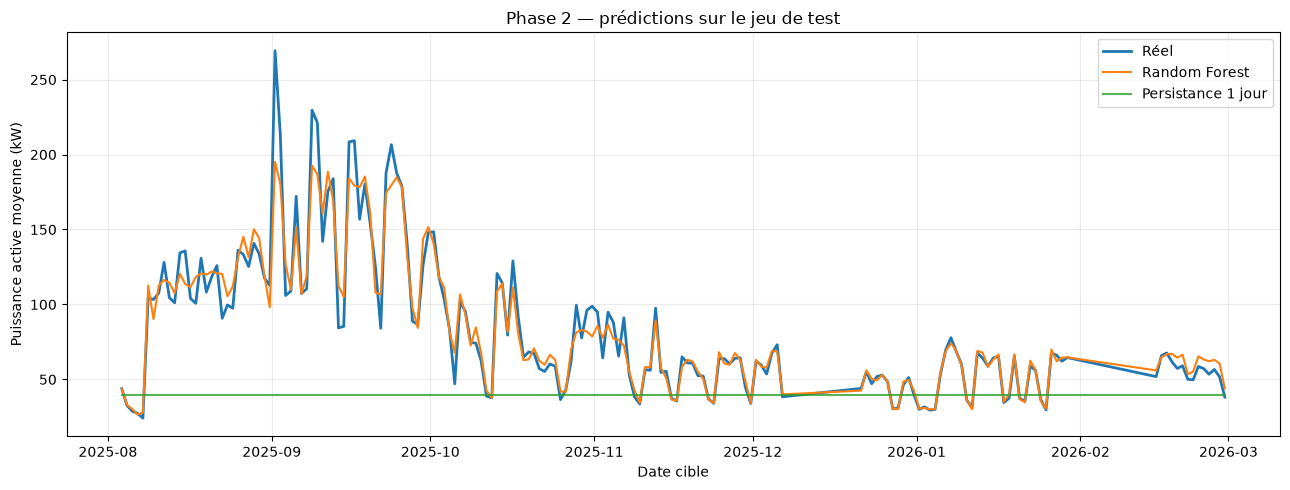

In [6]:
test_metadata = metadata.iloc[test_idx].reset_index(drop=True)
prediction_table = test_metadata[['target_timestamp']].copy()
prediction_table['y_true'] = y_test
for model_name, model_prediction in predictions['test'].items():
    prediction_table[f'prediction_{model_name}'] = model_prediction
prediction_table.to_csv(RESULTS_DIR / 'benchmark_predictions.csv', index=False)

plt.figure(figsize=(13, 5))
plt.plot(prediction_table['target_timestamp'], prediction_table['y_true'], label='Réel', linewidth=2)
plt.plot(prediction_table['target_timestamp'], prediction_table['prediction_random_forest'], label='Random Forest')
plt.plot(prediction_table['target_timestamp'], prediction_table['prediction_persistance_1_jour'], label='Persistance 1 jour', alpha=0.8)
plt.xlabel('Date cible')
plt.ylabel('Puissance active moyenne (kW)')
plt.title('Phase 2 — prédictions sur le jeu de test')
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RESULTS_DIR / '08_benchmark_predictions.png', dpi=160)
plt.show()

In [7]:
benchmark_spec = {
    'window_file': str(window_file.relative_to(PROJECT_ROOT)),
    'target': spec['target_column'],
    'split_fractions': {'train': 0.70, 'validation': 0.15, 'test': 0.15},
    'split_sizes': {name: int(len(index)) for name, index in splits.items()},
    'models': ['moyenne_entrainement', 'persistance_1_jour', 'random_forest'],
    'random_forest_estimators': 200,
    'random_forest_training_seconds': round(training_seconds, 3),
}
(RESULTS_DIR / 'benchmark_spec.json').write_text(
    json.dumps(benchmark_spec, ensure_ascii=False, indent=2),
    encoding='utf-8',
)
print('Fichiers générés :')
for output in ['benchmark_metrics.csv', 'benchmark_predictions.csv', 'benchmark_spec.json', '08_benchmark_predictions.png']:
    print(RESULTS_DIR / output)

Fichiers générés :
C:\Évaluation approfondie2\results\benchmark_metrics.csv
C:\Évaluation approfondie2\results\benchmark_predictions.csv
C:\Évaluation approfondie2\results\benchmark_spec.json
C:\Évaluation approfondie2\results\08_benchmark_predictions.png
